In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os

base = "/content/drive/MyDrive/sroie"

print("Folder exists:", os.path.exists(base))
print("Contents:", os.listdir(base) if os.path.exists(base) else "Not found")

Folder exists: True
Contents: ['0325updated.task2train(626p)', '0325updated.task1train(626p)']


In [3]:
import os

base = "/content/drive/MyDrive/sroie"

# Auto-detect task2 folder name on Google Drive (handles ' (1)' or standard naming)
candidates = [
    os.path.join(base, "0325updated.task2train(626p)"),
    os.path.join(base, "0325updated.task2train(626p) (1)")
]
task2 = next((c for c in candidates if os.path.exists(c)), candidates[0])

print("Task2 folder path:", task2)
print("Folder exists:", os.path.exists(task2))
if os.path.exists(task2):
    items = os.listdir(task2)
    print("Number of items:", len(items))
    print("\nPreview first 10 files:")
    for name in items[:10]:
        print(name)
else:
    print("WARNING: Folder not found! Check your Google Drive directory.")


Task2 folder path: /content/drive/MyDrive/sroie/0325updated.task2train(626p)
Folder exists: True
Number of items: 1611

Preview first 10 files:
X51005757294 (1).jpg
X51005757324 (1).jpg
X51005757346 (1).jpg
X51005806679 (2).txt
X51005806698 (2).txt
X51005806685 (2).txt
X51005806703 (2).txt
X51005806702 (2).txt
X51005806702 (1).jpg
X51005806716 (1).jpg


In [4]:
from pathlib import Path

files = list(Path(task2).iterdir())

images = {p.stem for p in files if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
labels = {p.stem for p in files if p.suffix.lower() == ".txt"}

print("Images:", len(images))
print("Annotations:", len(labels))
print("Matched pairs:", len(images & labels))
print("Images without annotations:", len(images - labels))
print("Annotations without images:", len(labels - images))

Images: 735
Annotations: 876
Matched pairs: 727
Images without annotations: 8
Annotations without images: 149


In [5]:
from pathlib import Path
from collections import Counter
import json

root = Path(task2)
files = list(root.iterdir())

print("File extensions:", Counter(p.suffix.lower() for p in files))

print("\nSample images:")
for p in sorted(root.glob("*.jpg"))[:15]:
    print(p.name)

print("\nSample annotation contents:")
for p in sorted(root.glob("*.txt"))[:3]:
    print(f"\n--- {p.name} ---")
    try:
        print(json.dumps(json.loads(p.read_text(encoding="utf-8")), indent=2))
    except Exception as e:
        print("Could not parse as JSON:", e)
        print(p.read_text(encoding="utf-8", errors="replace")[:500])

File extensions: Counter({'.txt': 876, '.jpg': 735})

Sample images:
X00016469612.jpg
X00016469619.jpg
X00016469620.jpg
X00016469622.jpg
X00016469623.jpg
X00016469669.jpg
X00016469672.jpg
X00016469676.jpg
X51005200938.jpg
X51005230617.jpg
X51005255805.jpg
X51005268200.jpg
X51005268262.jpg
X51005268400.jpg
X51005268472.jpg

Sample annotation contents:

--- X00016469612.txt ---
{
  "company": "BOOK TA .K (TAMAN DAYA) SDN BHD",
  "date": "25/12/2018",
  "address": "NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.",
  "total": "9.00"
}

--- X00016469619.txt ---
{
  "company": "INDAH GIFT & HOME DECO",
  "date": "19/10/2018",
  "address": "27, JALAN DEDAP 13, TAMAN JOHOR JAYA, 81100 JOHOR BAHRU, JOHOR.",
  "total": "60.30"
}

--- X00016469620.txt ---
{
  "company": "MR D.I.Y. (JOHOR) SDN BHD",
  "date": "12-01-19",
  "address": "LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERINDUSTRIAN BALAKONG, 43300 SERI KEMBANGAN, SELANGOR (MR DIY TESCO TERBAU)",
  "total": "33.90"
}


In [6]:
import re
from collections import defaultdict

def normalized_stem(name):
    # Remove a trailing copy suffix such as " (1)" or " (2)"
    return re.sub(r" \(\d+\)$", "", Path(name).stem)

images_by_id = defaultdict(list)
labels_by_id = defaultdict(list)

for p in files:
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        images_by_id[normalized_stem(p.name)].append(p.name)
    elif p.suffix.lower() == ".txt":
        labels_by_id[normalized_stem(p.name)].append(p.name)

image_ids = set(images_by_id)
label_ids = set(labels_by_id)

print("Matched after suffix normalization:", len(image_ids & label_ids))
print("Images still unmatched:", len(image_ids - label_ids))
print("Annotations still unmatched:", len(label_ids - image_ids))

print("\nExample duplicate image IDs:")
for key, names in images_by_id.items():
    if len(names) > 1:
        print(key, "->", names[:5])

Matched after suffix normalization: 626
Images still unmatched: 0
Annotations still unmatched: 0

Example duplicate image IDs:
X51005757294 -> ['X51005757294 (1).jpg', 'X51005757294.jpg']
X51005757324 -> ['X51005757324 (1).jpg', 'X51005757324.jpg']
X51005757346 -> ['X51005757346 (1).jpg', 'X51005757346.jpg']
X51005806702 -> ['X51005806702 (1).jpg', 'X51005806702.jpg']
X51005806716 -> ['X51005806716 (1).jpg', 'X51005806716.jpg']
X51005757349 -> ['X51005757349 (2).jpg', 'X51005757349 (1).jpg', 'X51005757349.jpg']
X51005763940 -> ['X51005763940 (2).jpg', 'X51005763940 (1).jpg', 'X51005763940.jpg']
X51005757351 -> ['X51005757351 (2).jpg', 'X51005757351 (1).jpg', 'X51005757351.jpg']
X51005757353 -> ['X51005757353 (2).jpg', 'X51005757353 (1).jpg', 'X51005757353.jpg']
X51005757304 -> ['X51005757304.jpg', 'X51005757304 (1).jpg']
X51005757323 -> ['X51005757323.jpg', 'X51005757323 (1).jpg']
X51006311779 -> ['X51006311779 (1).jpg', 'X51006311779.jpg']
X51006311767 -> ['X51006311767 (1).jpg', 'X51

In [7]:
from pathlib import Path
from collections import defaultdict
import json
import re

root = Path(task2)

def original_id(filename):
    return re.sub(r" \(\d+\)$", "", Path(filename).stem)

images_by_id = defaultdict(list)
labels_by_id = defaultdict(list)

for p in root.iterdir():
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        images_by_id[original_id(p.name)].append(p)
    elif p.suffix.lower() == ".txt":
        labels_by_id[original_id(p.name)].append(p)

# Only IDs with exactly one image and exactly one annotation
clean_ids = sorted(
    image_id
    for image_id in set(images_by_id) & set(labels_by_id)
    if len(images_by_id[image_id]) == 1
    and len(labels_by_id[image_id]) == 1
)

records = []

for image_id in clean_ids:
    image_path = images_by_id[image_id][0]
    label_path = labels_by_id[image_id][0]

    try:
        label = json.loads(label_path.read_text(encoding="utf-8"))
        required = {"company", "date", "address", "total"}

        if not required.issubset(label):
            continue

        records.append({
            "id": image_id,
            "image_path": str(image_path),
            "label_path": str(label_path),
            "ground_truth": label
        })
    except (json.JSONDecodeError, OSError):
        continue

print("Unique, unambiguous image-label pairs:", len(records))
print("Example record:")
print(json.dumps(records[0], indent=2, ensure_ascii=False) if records else "No valid records")

Unique, unambiguous image-label pairs: 437
Example record:
{
  "id": "X00016469612",
  "image_path": "/content/drive/MyDrive/sroie/0325updated.task2train(626p)/X00016469612.jpg",
  "label_path": "/content/drive/MyDrive/sroie/0325updated.task2train(626p)/X00016469612.txt",
  "ground_truth": {
    "company": "BOOK TA .K (TAMAN DAYA) SDN BHD",
    "date": "25/12/2018",
    "address": "NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.",
    "total": "9.00"
  }
}


In [8]:
import os
import json
from pathlib import Path

manifest_path = "/content/drive/MyDrive/doc-extract-ai/manifests/sroie_split_seed42.json"

def resolve_existing_path(p: str) -> str:
    """Resolve path whether the folder on Drive has ' (1)' or not, using detected task2 folder."""
    if os.path.exists(p):
        return p
    # Try resolving via detected task2 folder
    if "task2" in globals() and os.path.exists(task2):
        candidate = os.path.join(task2, os.path.basename(p))
        if os.path.exists(candidate):
            return candidate
    # Fallback substring replacements
    p_no_copy = p.replace("0325updated.task2train(626p) (1)", "0325updated.task2train(626p)")
    if os.path.exists(p_no_copy):
        return p_no_copy
    p_with_copy = p.replace("0325updated.task2train(626p)", "0325updated.task2train(626p) (1)")
    if os.path.exists(p_with_copy):
        return p_with_copy
    return p

if os.path.exists(manifest_path):
    print(f"Loading existing fixed manifest: {manifest_path}")
    with open(manifest_path, "r", encoding="utf-8") as f:
        manifest = json.load(f)

    # Auto-sanitize paths in case folder name in Drive changed
    path_fixed_count = 0
    for r in manifest:
        orig_img = r["image_path"]
        orig_lbl = r["label_path"]
        r["image_path"] = resolve_existing_path(r["image_path"])
        r["label_path"] = resolve_existing_path(r["label_path"])
        if r["image_path"] != orig_img or r["label_path"] != orig_lbl:
            path_fixed_count += 1

    if path_fixed_count > 0:
        print(f"Auto-corrected folder paths for {path_fixed_count} records to match Drive!")
        with open(manifest_path, "w", encoding="utf-8") as f:
            json.dump(manifest, f, indent=2)
        print("Updated manifest on Drive with corrected paths.")

    train_records = [r for r in manifest if r["split"] == "development"]
    test_records = [r for r in manifest if r["split"] == "held_out"]
    print(f"Loaded {len(train_records)} development records and {len(test_records)} held-out records.")
else:
    from sklearn.model_selection import train_test_split
    train_records, test_records = train_test_split(
        records,
        test_size=0.20,
        random_state=42,
        shuffle=True
    )
    manifest_dir = os.path.dirname(manifest_path)
    os.makedirs(manifest_dir, exist_ok=True)
    def manifest_rows(items, split):
        return [
            {
                "id": r["id"],
                "image_path": r["image_path"],
                "label_path": r["label_path"],
                "split": split
            }
            for r in items
        ]
    manifest = (
        manifest_rows(train_records, "development")
        + manifest_rows(test_records, "held_out")
    )
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)
    print(f"Created and saved split manifest: {manifest_path}")

print(f"\nDevelopment split count: {len(train_records)}")
print(f"Held-out split count: {len(test_records)}")
print("\n[Protocol Enforced]: All baseline development and parameter tuning are restricted")
print("strictly to the 349 development records. The 88 held-out records remain unaccessed.")


Loading existing fixed manifest: /content/drive/MyDrive/doc-extract-ai/manifests/sroie_split_seed42.json
Auto-corrected folder paths for 437 records to match Drive!
Updated manifest on Drive with corrected paths.
Loaded 349 development records and 88 held-out records.

Development split count: 349
Held-out split count: 88

[Protocol Enforced]: All baseline development and parameter tuning are restricted
strictly to the 349 development records. The 88 held-out records remain unaccessed.


In [9]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract pillow pandas rapidfuzz

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 86.4 MB/s eta 0:00:00


In [10]:
import pytesseract
from PIL import Image
import pandas as pd
import rapidfuzz

print("Tesseract version:", pytesseract.get_tesseract_version())
print("OCR dependencies installed successfully.")

Tesseract version: 5.3.4
OCR dependencies installed successfully.


In [11]:
import os
import pytesseract
from PIL import Image

sample = train_records[0]
print("Receipt ID:", sample["id"])
print("Image Path:", sample["image_path"])
print("Image exists on disk:", os.path.exists(sample["image_path"]))

if not os.path.exists(sample["image_path"]):
    raise FileNotFoundError(f"Image file not found: {sample['image_path']}\nEnsure Cell 8 was executed to auto-correct paths.")

image = Image.open(sample["image_path"]).convert("RGB")
print("Image loaded successfully. Size:", image.size)

# Initial baseline OCR without preprocessing (diagnostics)
ocr_text = pytesseract.image_to_string(image)
print(f"Initial raw OCR character count: {len(ocr_text)}")


Receipt ID: X51006619862
Image Path: /content/drive/MyDrive/sroie/0325updated.task2train(626p)/X51006619862.jpg
Image exists on disk: True
Image loaded successfully. Size: (884, 1833)
Initial raw OCR character count: 0


In [12]:
print("Receipt ID:", sample["id"])
print("Image size:", image.size)
print("OCR character count:", len(ocr_text))
print("\nFull OCR output:\n")
print(repr(ocr_text))

Receipt ID: X51006619862
Image size: (884, 1833)
OCR character count: 0

Full OCR output:

''


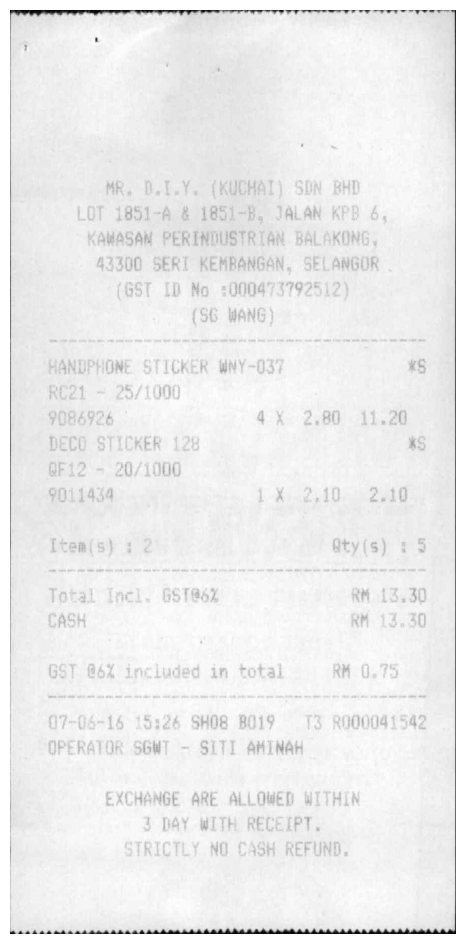

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 12))
plt.imshow(image)
plt.axis("off")
plt.show()

In [14]:
for psm in [3, 4, 6, 11]:
    config = f"--oem 3 --psm {psm}"
    text = pytesseract.image_to_string(image, config=config)

    print(f"\n--- PSM {psm}: {len(text)} characters ---")
    print(text[:1500] if text.strip() else "[No text detected]")



--- PSM 3: 0 characters ---
[No text detected]

--- PSM 4: 0 characters ---
[No text detected]

--- PSM 6: 3 characters ---
Se


--- PSM 11: 82 characters ---
ee ae ee ee SL le eee

‘a iti

Pe ere ee ee eee eee eT OU OO OUT YT OUT TTC UT UT



In [15]:
print(pytesseract.get_languages(config=""))
print("Image mode:", image.mode)
print("Image dimensions:", image.size)

['eng', 'osd']
Image mode: RGB
Image dimensions: (884, 1833)


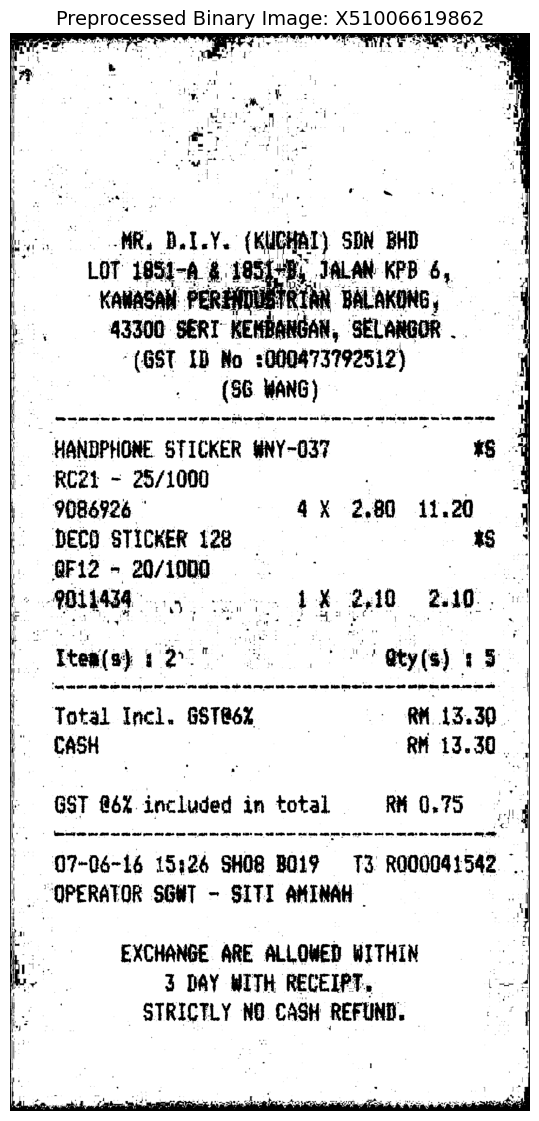

In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def preprocess_image_cv(img):
    """Enhance receipt image contrast, resolution, and sharpness for Tesseract OCR."""
    # Convert PIL Image to grayscale numpy array
    gray = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2GRAY)

    # 2x upscale with cubic interpolation for cleaner text edges
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

    # Improve local contrast with CLAHE
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)

    # Unsharp masking
    blurred = cv2.GaussianBlur(enhanced, (0, 0), 2)
    sharpened = cv2.addWeighted(enhanced, 1.8, blurred, -0.8, 0)

    # Otsu binarization
    binary = cv2.threshold(sharpened, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    return binary

# Preprocess the sample receipt and visualize
binary = preprocess_image_cv(image)

plt.figure(figsize=(10, 14))
plt.imshow(binary, cmap="gray")
plt.axis("off")
plt.title(f"Preprocessed Binary Image: {sample['id']}", fontsize=14)
plt.show()


In [17]:
def run_tesseract_ocr(img, psm=3):
    """Run Tesseract OCR on a receipt with OpenCV preprocessing."""
    binary_img = preprocess_image_cv(img)
    config = f"--oem 3 --psm {psm}"
    return pytesseract.image_to_string(binary_img, config=config)

# Run OCR on preprocessed sample with PSM 3 (identified as optimal in diagnostics)
ocr_text = run_tesseract_ocr(image, psm=3)

print(f"Receipt ID: {sample['id']}")
print(f"OCR Character Count: {len(ocr_text.strip())}")
print("\n--- Full OCR Output (first 1000 characters) ---\n")
print(ocr_text[:1000] if ocr_text.strip() else "[No text detected]")


Receipt ID: X51006619862
OCR Character Count: 772

--- Full OCR Output (first 1000 characters) ---

Me DALY (Kuck) SIN BHD
$188 2 JALAN KPB 6,
ail PER; HUUBTRIAN BALAKONG,
43300 SERT- RENN, ‘SELANGOR .
“(GST ID No 1000473792512)
| (86 Wane)

| HANDPHONE STICKER WnY-037

RC2t - 28/1000 . :
9086926 AX 2,80 11.20
DECO STICKER 128 OO
| 8F12 = 20/1000
Er POLAT oi AE, 2 10 2.10.

i Ttea(s) t > ee | * @ty(s) 1 5

et) og om ew ann 00 nd am en dt OR MG at Ub ome ote Ae ub bine 0D Ae are eat ime Ok aoe woe ous ait -

Total Incl. GSTR6X = RM ATL
CASH : RH 13.30,

“ast Qbx. included i in total —-RM 0.75

. ra
. fem cacy wm ne re stn ene es pom fe a Oe mE, HOY ONE OID OS LA OD Re Lees SO OR 9 Re oe HOE NO OEE RS. Rew Om seo YY, 4
’

7-06-16 15426 SHOR BOLTS ROOODALSAZ ~
| OPERATOR SGHT - SITI AMINAH

EXCHANGE ARE ALLOWED WITHIN
3 DAY WITH RECEIPT,
STRICTLY NO. CASH REFUND.




In [18]:
import re
import json

HEADER_NOISE = {
    "tax invoice", "invoice", "receipt", "official receipt",
    "simplified tax invoice", "cash receipt", "cash bill",
    "welcome", "thank you", "duplicate", "copy", "original",
    "order", "table", "sales receipt", "bill",
}

ADDRESS_KEYWORDS = [
    r"\blot\b", r"\bjalan\b", r"\bjln\b",
    r"\bstreet\b", r"\broad\b", r"\btaman\b", r"\blorong\b",
    r"\bkampung\b", r"\bkawasan\b", r"\bperindustrian\b",
    r"\bbandar\b", r"\btingkat\b", r"\bblok\b", r"\bseksyen\b",
    r"\barea\b", r"\bnagar\b", r"\bdistrict\b", r"\bsuite\b",
    r"\bselangor\b", r"\bkuala lumpur\b", r"\bjohor\b", r"\bpenang\b",
    r"\bpulau pinang\b", r"\bperak\b", r"\bkedah\b", r"\bmelaka\b",
    r"\bnegeri sembilan\b", r"\bpahang\b", r"\bkelantan\b",
    r"\bsarawak\b", r"\bsabah\b", r"\bmalaysia\b",
    r"\b\d{5}\b",
    r"(?<!receipt\s)(?<!invoice\s)(?<!inv\s)\bno\.?\s*\d+\b",
]

DATE_PATTERNS = [
    r"\b(\d{1,2}[/-]\d{1,2}[/-]\d{2,4})\b",
    r"\b(\d{4}[/-]\d{1,2}[/-]\d{1,2})\b",
    r"\b(\d{1,2}\.\d{1,2}\.\d{2,4})\b",
    r"\b(\d{1,2}[-\s]+(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*[-\s]+\d{2,4})\b",
    r"\b((?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\s+\d{1,2},?\s+\d{2,4})\b",
]

AMOUNT_PATTERN = re.compile(
    r"(?:RM|\$|USD)?\s*([0-9]{1,4}(?:,[0-9]{3})*\.[0-9]{2})\b",
    re.IGNORECASE
)

TOTAL_KEYWORDS = [
    r"\bgrand\s*total\b",
    r"\btotal\s*amount\b",
    r"\btotal\s*incl\.?\s*gst\b",
    r"\btotal\s*\(incl\.?\s*gst\b",
    r"\btotal\s*rm\b",
    r"\bnet\s*total\b",
    r"\bjumlah\b",
    r"\btotal\b",
    r"\bamount\s*due\b",
    r"\bbalance\s*due\b",
]

def extract_candidates(ocr_text):
    """Extract candidate lines and tokens from OCR text."""
    raw_lines = [l.strip() for l in ocr_text.splitlines() if l.strip()]

    dates = []
    for line in raw_lines:
        for pat in DATE_PATTERNS:
            for m in re.finditer(pat, line, re.IGNORECASE):
                dates.append(m.group(1).strip())

    amounts = []
    for line in raw_lines:
        for m in AMOUNT_PATTERN.finditer(line):
            amounts.append(m.group(1).replace(",", "").strip())

    total_lines = [
        (idx, line) for idx, line in enumerate(raw_lines)
        if any(re.search(kw, line.lower()) for kw in TOTAL_KEYWORDS)
    ]

    address_lines = [
        (idx, line) for idx, line in enumerate(raw_lines)
        if any(re.search(kw, line.lower()) for kw in ADDRESS_KEYWORDS)
    ]

    return {
        "raw_lines": raw_lines,
        "date_candidates": dates,
        "amount_candidates": amounts,
        "total_lines": total_lines,
        "address_lines": address_lines,
    }

def predict_company(raw_lines):
    """Predict company name from the top header lines."""
    for line in raw_lines[:6]:
        line_clean = line.strip()
        line_lower = line_clean.lower()
        if len(line_clean) < 3 or re.match(r"^[-=_*#\s|]+$", line_clean):
            continue
        if line_lower in HEADER_NOISE:
            continue
        if re.search(r"\b(tel|phone|fax|gst|reg|roc|ssm|co\.\s*no|tax\s*id)\b", line_lower):
            continue
        if re.match(r"^\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}", line_clean):
            continue
        cleaned = re.sub(r"^[|\-_=*~#\s]+|[|\-_=*~#\s]+$", "", line_clean).strip()
        if len(cleaned) >= 3:
            return cleaned
    return raw_lines[0] if raw_lines else None

def predict_date(raw_lines, date_candidates):
    """Predict date, prioritizing lines with 'date' or 'time'."""
    for line in raw_lines:
        line_lower = line.lower()
        if any(kw in line_lower for kw in ["date", "time", "tarikh", "dt", "d/t"]):
            for pat in DATE_PATTERNS:
                m = re.search(pat, line, re.IGNORECASE)
                if m:
                    cand = m.group(1).strip()
                    if is_plausible_date(cand):
                        return cand
    for cand in date_candidates:
        if is_plausible_date(cand):
            return cand
    return date_candidates[0] if date_candidates else None

def is_plausible_date(text):
    digits = re.findall(r"\d+", text)
    if len(digits) == 3:
        nums = [int(d) for d in digits]
        has_year = any((2000 <= n <= 2035) or (10 <= n <= 35) for n in nums)
        has_day = any(1 <= n <= 31 for n in nums)
        has_month = any(1 <= n <= 12 for n in nums)
        return has_year and has_day and has_month
    return len(digits) >= 2

def predict_address(raw_lines, address_lines):
    """Predict address from header candidate lines."""
    if not address_lines:
        return None
    neg = ["total", "subtotal", "gst", "tax invoice", "receipt no", "rcp-", "invoice no", "table", "cashier", "order", "date:", "tel:"]
    header_addrs = [
        line for idx, line in address_lines
        if 0 < idx <= 10 and not any(kw in line.lower() for kw in neg)
    ]
    if header_addrs:
        combined = ", ".join(header_addrs[:3])
        cleaned = re.sub(r"[|~_]+", " ", combined)
        return re.sub(r"\s+", " ", cleaned).strip()
    return address_lines[0][1].strip()

def predict_total(raw_lines, total_lines, amount_candidates):
    """Predict total amount, prioritizing explicit total lines."""
    priority_lines = []
    standard_lines = []
    for _, line in total_lines:
        line_lower = line.lower()
        if any(neg in line_lower for neg in ["subtotal", "sub total", "change", "total item", "total qty"]):
            continue
        if any(re.search(kw, line_lower) for kw in [r"\bgrand\s*total\b", r"\btotal\s*incl", r"\btotal\s*\(incl", r"\bnet\s*total\b"]):
            priority_lines.append(line)
        else:
            standard_lines.append(line)
    for line in priority_lines:
        amounts = AMOUNT_PATTERN.findall(line)
        if amounts:
            return amounts[-1].replace(",", "").strip()
    for line in reversed(standard_lines):
        amounts = AMOUNT_PATTERN.findall(line)
        if amounts:
            return amounts[-1].replace(",", "").strip()
    if amount_candidates:
        try:
            floats = sorted([(float(a), a) for a in amount_candidates], key=lambda x: x[0], reverse=True)
            return floats[0][1]
        except ValueError:
            return amount_candidates[-1]
    return None

def predict_receipt_fields(text):
    """End-to-end baseline predictor for the 4 SROIE target fields."""
    cands = extract_candidates(text)
    lines = cands["raw_lines"]
    return {
        "company": predict_company(lines),
        "date": predict_date(lines, cands["date_candidates"]),
        "address": predict_address(lines, cands["address_lines"]),
        "total": predict_total(lines, cands["total_lines"], cands["amount_candidates"]),
    }

# Run extraction on sample ocr_text
candidates = extract_candidates(ocr_text)
predictions = predict_receipt_fields(ocr_text)

print("--- CANDIDATE EXTRACTIONS ---")
print(json.dumps({k: v for k, v in candidates.items() if k != "raw_lines"}, indent=2))

print("\n--- PREDICTED SROIE FIELDS ---")
print(json.dumps(predictions, indent=2))


--- CANDIDATE EXTRACTIONS ---
{
  "date_candidates": [
    "7-06-16"
  ],
  "amount_candidates": [
    "11.20",
    "2.10",
    "13.30",
    "0.75"
  ],
  "total_lines": [
    [
      14,
      "Total Incl. GSTR6X = RM ATL"
    ],
    [
      16,
      "\u201cast Qbx. included i in total \u2014-RM 0.75"
    ]
  ],
  "address_lines": [
    [
      1,
      "$188 2 JALAN KPB 6,"
    ],
    [
      3,
      "43300 SERT- RENN, \u2018SELANGOR ."
    ],
    [
      4,
      "\u201c(GST ID No 1000473792512)"
    ],
    [
      20,
      "7-06-16 15426 SHOR BOLTS ROOODALSAZ ~"
    ]
  ]
}

--- PREDICTED SROIE FIELDS ---
{
  "company": "Me DALY (Kuck) SIN BHD",
  "date": "7-06-16",
  "address": "$188 2 JALAN KPB 6,, 43300 SERT- RENN, \u2018SELANGOR .",
  "total": "0.75"
}


In [19]:
from rapidfuzz import fuzz
from datetime import datetime

# Normalization helpers
def normalize_company(text):
    if not text:
        return ""
    s = str(text).lower().strip()
    s = re.sub(r"[^\w\s]", " ", s)
    s = re.sub(r"\b(sdn\s*bhd|sdn|bhd|pte\s*ltd|ltd|inc|llc|co|corp)\b", "", s)
    return " ".join(s.split())

def normalize_date(text):
    if not text:
        return ""
    s = str(text).strip()
    if re.match(r"^\d{4}-\d{2}-\d{2}$", s):
        return s
    for fmt in ["%d/%m/%Y", "%d/%m/%y", "%d-%m-%Y", "%d-%m-%y", "%d.%m.%Y", "%d.%m.%y", "%Y/%m/%d", "%d %b %Y", "%d %B %Y", "%d-%b-%Y"]:
        try:
            return datetime.strptime(s, fmt).strftime("%Y-%m-%d")
        except ValueError:
            continue
    return re.sub(r"[^\w]", "", s.lower())

def normalize_address(text):
    if not text:
        return ""
    s = str(text).lower()
    s = re.sub(r"[^\w\s]", " ", s)
    return " ".join(s.split())

def normalize_total(val):
    if val is None or val == "":
        return None
    if isinstance(val, (int, float)):
        return round(float(val), 2)
    s = str(val).replace("$", "").replace("RM", "").replace("rm", "").replace(",", "").strip()
    try:
        return round(float(s), 2)
    except ValueError:
        return None

def match_field(pred_val, gt_val, field_name):
    pred_str = str(pred_val).strip() if pred_val is not None else ""
    gt_str = str(gt_val).strip() if gt_val is not None else ""
    exact = (pred_str == gt_str) and (len(gt_str) > 0)
    score = float(fuzz.token_set_ratio(pred_str.lower(), gt_str.lower())) if pred_str and gt_str else 0.0

    norm_match = False
    if field_name == "total":
        p_num = normalize_total(pred_val)
        g_num = normalize_total(gt_val)
        norm_match = (p_num is not None) and (g_num is not None) and (abs(p_num - g_num) < 0.01)
    elif field_name == "date":
        p_date = normalize_date(pred_val)
        g_date = normalize_date(gt_val)
        norm_match = (p_date == g_date) and (len(g_date) > 0)
    elif field_name == "company":
        p_comp = normalize_company(pred_val)
        g_comp = normalize_company(gt_val)
        norm_match = (p_comp == g_comp and len(g_comp) > 0) or (score >= 85.0)
    elif field_name == "address":
        p_addr = normalize_address(pred_val)
        g_addr = normalize_address(gt_val)
        norm_match = (p_addr == g_addr and len(g_addr) > 0) or (score >= 80.0)
    else:
        norm_match = exact

    return exact, norm_match, score

# Load ground truth for sample
with open(sample["label_path"], "r", encoding="utf-8") as f:
    ground_truth = json.load(f)

# Display side-by-side single-sample evaluation
comparison_rows = []
for field in ["company", "date", "address", "total"]:
    p_val = predictions.get(field)
    g_val = ground_truth.get(field)
    exact, norm_m, score = match_field(p_val, g_val, field)
    comparison_rows.append({
        "Field": field,
        "Predicted": str(p_val),
        "Ground Truth": str(g_val),
        "Exact Match": "PASS" if exact else "FAIL",
        "Normalized Match": "PASS" if norm_m else "FAIL",
        "RapidFuzz Score": round(score, 1)
    })

eval_df = pd.DataFrame(comparison_rows)
print(f"Receipt ID: {sample['id']}")
print("--- SINGLE SAMPLE EVALUATION ---")
display(eval_df)


Receipt ID: X51006619862
--- SINGLE SAMPLE EVALUATION ---


,Field,Predicted,Ground Truth,Exact Match,Normalized Match,RapidFuzz Score
0,company,Me DALY (Kuck) SIN BHD,MR. D.I.Y. (KUCHAI) SDN BHD,FAIL,FAIL,69.4
1,date,7-06-16,07-06-16,FAIL,PASS,93.3
2,address,"$188 2 JALAN KPB 6,, 43300 SERT- RENN, ‘SELANG...","LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERI...",FAIL,FAIL,56.2
3,total,0.75,RM 13.30,FAIL,FAIL,16.7


In [20]:
from tqdm.notebook import tqdm
import os
import pandas as pd

# ==============================================================================
# BATCH BASELINE EVALUATION ON SROIE DEVELOPMENT SPLIT (N = 349)
# ==============================================================================
# Set MAX_DEV_SAMPLES = None to run the complete 349 development records.
# Or set to e.g. 30 for a quick 1-2 minute verification.
MAX_DEV_SAMPLES = None  # None for full 349 development set

records_to_evaluate = train_records[:MAX_DEV_SAMPLES] if MAX_DEV_SAMPLES else train_records
print(f"Starting Baseline Evaluation on {len(records_to_evaluate)} Development Records...")
print("Note: Held-out test set (88 records) remains completely untouched.\n")

results = []
fields = ["company", "date", "address", "total"]
stats = {f: {"exact": 0, "norm": 0, "score_sum": 0.0} for f in fields}

for rec in tqdm(records_to_evaluate, desc="Evaluating Dev Records"):
    doc_id = rec["id"]
    try:
        # 1. Load image and run preprocessed OCR
        img = Image.open(rec["image_path"]).convert("RGB")
        txt = run_tesseract_ocr(img, psm=3)

        # 2. Extract baseline predictions
        preds = predict_receipt_fields(txt)

        # 3. Load ground truth
        with open(rec["label_path"], "r", encoding="utf-8") as f:
            gt = json.load(f)

        row = {"id": doc_id, "char_count": len(txt.strip())}
        for f in fields:
            p_val = preds.get(f)
            g_val = gt.get(f)
            exact, norm_m, score = match_field(p_val, g_val, f)
            if exact:
                stats[f]["exact"] += 1
            if norm_m:
                stats[f]["norm"] += 1
            stats[f]["score_sum"] += score

            row[f"{f}_pred"] = p_val
            row[f"{f}_gt"] = g_val
            row[f"{f}_exact"] = exact
            row[f"{f}_norm"] = norm_m
            row[f"{f}_score"] = score

        results.append(row)
    except Exception as e:
        print(f"Error processing {doc_id}: {e}")
        continue

total_evaluated = len(results)
print(f"\nSuccessfully evaluated {total_evaluated} records.")

# Build summary metrics table
summary_rows = []
for f in fields:
    em_rate = (stats[f]["exact"] / total_evaluated) * 100.0 if total_evaluated else 0.0
    nm_rate = (stats[f]["norm"] / total_evaluated) * 100.0 if total_evaluated else 0.0
    avg_fuzz = stats[f]["score_sum"] / total_evaluated if total_evaluated else 0.0
    summary_rows.append({
        "Field": f,
        "Exact Match (%)": round(em_rate, 2),
        "Normalized Match (%)": round(nm_rate, 2),
        "Avg RapidFuzz Score": round(avg_fuzz, 2)
    })

# Compute Macro Averages
macro_em = sum(r["Exact Match (%)"] for r in summary_rows) / len(summary_rows)
macro_nm = sum(r["Normalized Match (%)"] for r in summary_rows) / len(summary_rows)
macro_fuzz = sum(r["Avg RapidFuzz Score"] for r in summary_rows) / len(summary_rows)

summary_rows.append({
    "Field": "MACRO AVERAGE",
    "Exact Match (%)": round(macro_em, 2),
    "Normalized Match (%)": round(macro_nm, 2),
    "Avg RapidFuzz Score": round(macro_fuzz, 2)
})

summary_df = pd.DataFrame(summary_rows)
details_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print(f" SROIE DEVELOPMENT SET BASELINE BENCHMARK (N = {total_evaluated})")
print("=" * 65)
display(summary_df)
print("=" * 65)

# Save evaluation results to Google Drive results folder
results_dir = "/content/drive/MyDrive/doc-extract-ai/results"
os.makedirs(results_dir, exist_ok=True)
summary_path = os.path.join(results_dir, "dev_baseline_summary.csv")
details_path = os.path.join(results_dir, "dev_baseline_details.csv")

summary_df.to_csv(summary_path, index=False)
details_df.to_csv(details_path, index=False)
print(f"\nResults saved successfully:")
print(f"  - Summary table: {summary_path}")
print(f"  - Detailed predictions: {details_path}")


Starting Baseline Evaluation on 349 Development Records...
Note: Held-out test set (88 records) remains completely untouched.



Evaluating Dev Records:   0%|          | 0/349 [00:00<?, ?it/s]


Successfully evaluated 349 records.

 SROIE DEVELOPMENT SET BASELINE BENCHMARK (N = 349)


,Field,Exact Match (%),Normalized Match (%),Avg RapidFuzz Score
0,company,12.32,39.26,55.42
1,date,57.88,68.19,77.52
2,address,0.00,69.05,79.54
3,total,39.54,52.44,74.79
4,MACRO AVERAGE,27.44,57.23,71.82



Results saved successfully:
  - Summary table: /content/drive/MyDrive/doc-extract-ai/results/dev_baseline_summary.csv
  - Detailed predictions: /content/drive/MyDrive/doc-extract-ai/results/dev_baseline_details.csv
